# Avance 4. Modelos alternativos
**Proyecto Berry-Vision — Clasificación de arándanos defectuosos mediante visión computacional e inteligencia artificial**

**Equipo #6** · Proyecto Integrador MNA · Metodología CRISP-ML(Q), fase *Modeling*

| Integrante | Matrícula |
|---|---|
| José Luis Parada Gutiérrez | A00939669 |
| Kevin Rosario Cota Rodríguez | A01796705 |
| Rolando David Villarreal Martínez | A00609894 |

---
**Objetivos del avance**
- 3.3 Explorar una gama diversa de técnicas y enfoques para identificar el de mejor desempeño en el conjunto de datos.
- 3.4 Encontrar la configuración óptima que maximiza el rendimiento del modelo.

**Punto de partida.** El Avance 3 fijó el baseline (regresión logística), la métrica y los criterios mínimos sobre las 15 características del Avance 2. Aquí se construyen **ocho modelos alternativos individuales (sin ensambles) de familias distintas** —seis sobre las características tabulares y dos sobre las imágenes (ResNet18 preentrenada y una CNN propia, a partir del trabajo de José Luis)—, se comparan entre sí y contra el baseline con un mismo protocolo, se **ajustan los dos mejores** y se **elige un modelo individual final**. El baseline del Avance 3 (regresión logística) no compite por el ajuste: es la **referencia** que cada alternativa debe igualar o superar para justificarse.

| Paso solicitado | Sección |
|---|---|
| Construir ≥ 6 modelos individuales de algoritmos variados (más el baseline como referencia) | 2 |
| Compararlos (métrica principal, ≥ 2 métricas más y tiempos) | 3 |
| Seleccionar los dos mejores alternativos | 4 |
| Ajustar los dos mejores (búsqueda de hiperparámetros) | 5 |
| Elegir el modelo individual final | 6 |

**Protocolo (el mismo del Avance 3).** Las particiones train/val/test y los bloques de captura son los del Avance 2. La comparación, la selección y el ajuste usan **solo validación cruzada agrupada sobre *train*** (un bloque nunca se parte entre pliegues); *validación* es una comprobación independiente; el conjunto de **prueba se toca una sola vez**, en la sección 7.

## 1. Configuración y datos

In [1]:
import os, sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef, accuracy_score, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 200)
SEED = 42

# ---- Rutas: Colab (Drive) o ejecución local -------------------------------------------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _base = Path("/content/drive/MyDrive/ProyectoIntegrador/Datos")
else:
    _base = next((p for p in [Path("../Datos"), Path("Datos")] if p.exists()), Path("../Datos"))
A2_DIR = Path(os.environ.get("BERRY_IN_DIR", _base / "resultados_avance2"))      # tablas del Avance 2
A3_DIR = Path(os.environ.get("BERRY_A3_DIR", _base / "resultados_avance3"))      # baseline del Avance 3
OUT_DIR = Path(os.environ.get("BERRY_OUT_DIR", _base / "resultados_avance4"))    # salidas de este avance
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Avance 2:", A2_DIR.resolve(), "\nAvance 3:", A3_DIR.resolve(), "\nSalidas :", OUT_DIR.resolve(), "| Colab:", IN_COLAB)

Mounted at /content/drive
Avance 2: /content/drive/.shortcut-targets-by-id/1D3LM7dIWfg66NB2euECFRQF0hvwhPH31/ProyectoIntegrador/Datos/resultados_avance2 
Avance 3: /content/drive/.shortcut-targets-by-id/1D3LM7dIWfg66NB2euECFRQF0hvwhPH31/ProyectoIntegrador/Datos/resultados_avance3 
Salidas : /content/drive/.shortcut-targets-by-id/1D3LM7dIWfg66NB2euECFRQF0hvwhPH31/ProyectoIntegrador/Datos/resultados_avance4 | Colab: True


In [2]:
TR, VA, TE = [pd.read_csv(A2_DIR / f"features_seleccionadas_{s}.csv") for s in ("train", "val", "test")]
META = ["crop_id", "grupo", "clase", "particion", "y"]
FEATS = [c for c in TR.columns if c not in META + ["defecto"]]
assert list(TR[FEATS].columns) == list(VA[FEATS].columns) == list(TE[FEATS].columns)
assert not set(TR.grupo) & set(VA.grupo) and not set(TR.grupo) & set(TE.grupo) and not set(VA.grupo) & set(TE.grupo)

Xtr, ytr, gtr = TR[FEATS], TR.y.values, TR.grupo.values
Xva, yva = VA[FEATS], VA.y.values
Xte, yte, gte = TE[FEATS], TE.y.values, TE.grupo.values
DEV = pd.concat([TR, VA], ignore_index=True)
Xdev, ydev = DEV[FEATS], DEV.y.values

display(pd.DataFrame({"recortes": [len(TR), len(VA), len(TE)], "malos": [ytr.sum(), yva.sum(), yte.sum()],
                      "% malos": [ytr.mean() * 100, yva.mean() * 100, yte.mean() * 100],
                      "bloques": [TR.grupo.nunique(), VA.grupo.nunique(), TE.grupo.nunique()]}, index=["train", "val", "test"]).round(1))
print(f"{len(FEATS)} características (ya estandarizadas con parámetros de train): {FEATS}")

# Configuración del baseline fijada en el Avance 3
cfg3 = json.load(open(A3_DIR / "config_baseline.json"))
C_BASE, U_BASE = float(cfg3["C"]), float(cfg3["umbral"])
print(f"Baseline del Avance 3: regresión logística con C = {C_BASE:g} y umbral = {U_BASE:.3f}")

,recortes,malos,% malos,bloques
train,258,95,36.8,60
val,45,16,35.6,11
test,50,20,40.0,13


15 características (ya estandarizadas con parámetros de train): ['rojez_std', 'rojez_p99', 'pct_marron', 'b_p95', 'rojez_p95', 'rojizo_ord', 'grad_p95', 'rugosidad_textura', 'indice_lesion', 'glcm_homogeneidad', 'densidad_bordes', 'nitidez', 'lbp_p6', 'matiz', 'a_medio']
Baseline del Avance 3: regresión logística con C = 0.316228 y umbral = 0.375


### 1.1 Imágenes: espacio de entrada de los modelos de visión
Además de la tabla de 15 características, dos modelos trabajan **directamente sobre los recortes** (los mismos 353 frutos, con el mismo identificador, las mismas particiones y los mismos bloques de captura):

| Espacio | Entrada | Modelos |
|---|---|---|
| `tab` | 15 características estandarizadas | Todos los modelos tabulares |
| `emb` | Embedding de 512 dimensiones de una **ResNet18 preentrenada en ImageNet con el *backbone* congelado** (se extrae una sola vez) | ResNet18 + regresión logística |
| `img` | Recorte de 128×128 píxeles, normalizado con la media y desviación del conjunto de entrenamiento | CNN propia |

El recorte sigue el criterio del Avance 1 (cuadrado de lado 2·(radio + 20) alrededor del fruto). La arquitectura de la CNN y el uso de ResNet18 congelada provienen del trabajo de José Luis; aquí se evalúan con el mismo protocolo que los demás modelos (validación cruzada agrupada) en lugar de una única partición de validación. Si la carpeta de imágenes no está disponible, la libreta omite estos dos modelos y compara solo los tabulares.

In [3]:
# ---- Imágenes (opcional): sin ellas se omiten los dos modelos de visión ------------------------------------
import copy
_cands = [os.environ.get("BERRY_IMG_DIR"), "/content/drive/MyDrive/ProyectoIntegrador/Semana4/v2" if IN_COLAB else None, "../Datos/Semana4/v2", "Datos/Semana4/v2"]
IMG_ROOT = next((Path(p) for p in _cands if p and (Path(p) / "output").exists() and (Path(p) / "etiquetas.csv").exists()), None)
HAY_IMG = IMG_ROOT is not None
ESPACIO = {}                                             # espacio de entrada de cada modelo (por defecto: tab)
ESPACIOS_X = {"tab": dict(tr=Xtr, va=Xva, dev=Xdev, te=Xte)}
MODELOS_IMG = {}
T_EMB = 0.0
if HAY_IMG:
    try:
        import torch, torch.nn as nn
        from PIL import Image
        from torchvision import models as tvm
        from sklearn.base import BaseEstimator, ClassifierMixin
        from sklearn.pipeline import Pipeline
        from sklearn.preprocessing import StandardScaler
        from sklearn.decomposition import PCA
        torch.set_num_threads(max(1, min(8, os.cpu_count() or 2)))

        et = pd.read_csv(IMG_ROOT / "etiquetas.csv", encoding="utf-8-sig")
        et["crop_id"] = et.nombre.str.replace(".png", "", regex=False)
        ALL = pd.concat([TR, VA, TE], ignore_index=True)[["crop_id", "grupo", "y"]].merge(
            et[["crop_id", "cx", "cy", "radio"]], on="crop_id", how="left", validate="one_to_one")
        assert ALL.cx.notna().all(), "hay recortes de las tablas sin imagen"

        def recorte(r, lado, pad=20):
            im = Image.open(IMG_ROOT / "output" / f"{r.crop_id}.png").convert("RGB"); w, h = im.size
            R = int(round(r.radio)) + pad; cx, cy = int(round(r.cx)), int(round(r.cy))
            c = im.crop((max(0, cx - R), max(0, cy - R), min(w, cx + R), min(h, cy + R)))
            return np.asarray(c.resize((lado, lado), Image.BILINEAR))
        I128 = np.stack([recorte(r, 128) for r in ALL.itertuples()]); I224 = np.stack([recorte(r, 224) for r in ALL.itertuples()])

        # (a) Embeddings de ResNet18 congelada (se calculan una vez; no hay entrenamiento del backbone)
        w = tvm.ResNet18_Weights.DEFAULT; red = tvm.resnet18(weights=w); red.fc = nn.Identity(); red.eval()
        mu = torch.tensor(w.transforms().mean).view(1, 3, 1, 1); sd = torch.tensor(w.transforms().std).view(1, 3, 1, 1)
        x = (torch.from_numpy(I224).permute(0, 3, 1, 2).float() / 255 - mu) / sd
        t0 = time.perf_counter()
        with torch.no_grad():
            EMB = torch.cat([red(x[i:i + 64]) for i in range(0, len(x), 64)]).numpy()
        T_EMB = time.perf_counter() - t0
        del x

        # (b) Tensor de la CNN propia (normalizado con estadísticos de train)
        T128 = torch.from_numpy(I128).permute(0, 3, 1, 2).float() / 255
        T128 = (T128 - T128[:len(TR)].mean((0, 2, 3), keepdim=True)) / T128[:len(TR)].std((0, 2, 3), keepdim=True)
        G_ALL = ALL.grupo.values

        class CNNBerry(BaseEstimator, ClassifierMixin):
            # CNN pequeña (4 bloques conv + pooling global) entrenada desde cero; ~20 % de los bloques de entrenamiento
            # se reserva para detener el entrenamiento (early stopping por AP)
            def __init__(self, base=16, dropout=0.4, activation="relu", lr=5e-4, weight_decay=1e-4, epochs=30, patience=6, batch=32, seed=SEED):
                self.base, self.dropout, self.activation, self.lr = base, dropout, activation, lr
                self.weight_decay, self.epochs, self.patience, self.batch, self.seed = weight_decay, epochs, patience, batch, seed
            def _red(self):
                act = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "elu": nn.ELU}[self.activation]; b = self.base
                blk = lambda i, o, pool=True: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), act()] + ([nn.MaxPool2d(2)] if pool else [])
                return nn.Sequential(*blk(3, b), *blk(b, 2 * b), *blk(2 * b, 4 * b), *blk(4 * b, 8 * b, False),
                                     nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(8 * b, 64), act(), nn.Dropout(self.dropout), nn.Linear(64, 1))
            def _p(self, idx):
                self.red_.eval(); out = []
                with torch.no_grad():
                    for i in range(0, len(idx), 128): out.append(torch.sigmoid(self.red_(T128[idx[i:i + 128]]).squeeze(1)))
                return torch.cat(out).numpy()
            def fit(self, X, y):
                idx = X["idx"].values.astype(int); y = np.asarray(y)
                torch.manual_seed(self.seed); rng = np.random.default_rng(self.seed)
                ti, vi = next(StratifiedGroupKFold(5, shuffle=True, random_state=self.seed).split(idx, y, G_ALL[idx]))
                self.red_ = self._red(); opt = torch.optim.AdamW(self.red_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
                perdida = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(y[ti] == 0).sum() / max((y[ti] == 1).sum(), 1)], dtype=torch.float32))
                mejor, estado, espera = -1.0, None, 0
                for ep in range(self.epochs):
                    self.red_.train(); orden = rng.permutation(ti)
                    for i in range(0, len(orden), self.batch):
                        b = orden[i:i + self.batch]
                        if len(b) < 2: continue
                        xb = T128[idx[b]]                                   # aumento de datos por lote: giros y rotaciones de 90°
                        if rng.random() < .5: xb = xb.flip(3)
                        if rng.random() < .5: xb = xb.flip(2)
                        xb = torch.rot90(xb, int(rng.integers(0, 4)), (2, 3))
                        opt.zero_grad(); perdida(self.red_(xb).squeeze(1), torch.tensor(y[b], dtype=torch.float32)).backward(); opt.step()
                    ap = average_precision_score(y[vi], self._p(idx[vi]))
                    if ap > mejor + 1e-4: mejor, estado, espera = ap, copy.deepcopy(self.red_.state_dict()), 0
                    else:
                        espera += 1
                        if espera >= self.patience: break
                self.red_.load_state_dict(estado); self.classes_ = np.array([0, 1]); self.mejor_epoca_ = ep + 1 - espera
                return self
            def predict_proba(self, X):
                p = self._p(X["idx"].values.astype(int)); return np.column_stack([1 - p, p])

        n_tr, n_va = len(TR), len(VA)
        def partir(F):
            return dict(tr=F.iloc[:n_tr].reset_index(drop=True), va=F.iloc[n_tr:n_tr + n_va].reset_index(drop=True),
                        dev=F.iloc[:n_tr + n_va].reset_index(drop=True), te=F.iloc[n_tr + n_va:].reset_index(drop=True))
        ESPACIOS_X["emb"] = partir(pd.DataFrame(EMB, columns=[f"e{i}" for i in range(EMB.shape[1])]))
        ESPACIOS_X["img"] = partir(pd.DataFrame({"idx": np.arange(len(ALL))}))
        MODELOS_IMG = {
            "ResNet18 + reg. logística": Pipeline([("sc", StandardScaler()), ("pca", PCA(64, random_state=SEED)),
                                                   ("clf", LogisticRegression(C=0.05, class_weight="balanced", max_iter=5000))]),
            "CNN propia": CNNBerry(),
        }
        ESPACIO.update({"ResNet18 + reg. logística": "emb", "CNN propia": "img"})
        print(f"Imágenes: {IMG_ROOT.resolve()} · {len(ALL)} recortes · embeddings ResNet18 {EMB.shape} calculados en {T_EMB:.1f} s")
    except Exception as e:
        HAY_IMG, MODELOS_IMG = False, {}
        print("Se omiten los modelos de imagen:", repr(e)[:300])
else:
    print("No se encontró la carpeta de imágenes (Semana4/v2): se omiten los dos modelos de visión.")
ES = lambda m: ESPACIOS_X[ESPACIO.get(m, "tab")]            # tablas (train/val/dev/test) del espacio de entrada de un modelo

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


Imágenes: /content/drive/.shortcut-targets-by-id/1D3LM7dIWfg66NB2euECFRQF0hvwhPH31/ProyectoIntegrador/Semana4/v2 · 353 recortes · embeddings ResNet18 (353, 512) calculados en 25.5 s


## 2. Métricas, protocolo y modelos candidatos

### 2.1 Qué se mide
Se mantiene el criterio del Avance 3: el error caro es el **falso negativo** (un fruto malo que pasa como bueno) y la clase de interés es la minoritaria (≈ 4 de cada 10 frutos). Como los modelos no producen probabilidades comparables al umbral 0.5 (algunos no admiten pesos de clase), la comparación se hace con métricas **independientes del umbral**, calculadas con predicciones fuera de pliegue:

| Métrica | Papel | Por qué |
|---|---|---|
| **AP** (*average precision*) | **Principal** (ordena la tabla y decide la selección) | Resume toda la curva precisión–recall; su referencia al azar es la prevalencia |
| **Precisión con recall ≥ 0.80** | Secundaria | Traduce el criterio de negocio del Avance 3 (C2/C3): ¿cuánta precisión queda cuando se exige detectar al menos 8 de cada 10 malos? |
| ROC-AUC | Secundaria | Capacidad global de ordenar *malo* sobre *bueno* |
| Tiempo de ajuste y de predicción | Costo | Requisito de la línea en tiempo real y de reentrenamiento |

El recall y la precisión a un umbral concreto se reportan para los dos modelos ajustados y para el modelo final (secciones 5–7), cuando ya se fijó el umbral con la regla del Avance 3.

### 2.2 Los modelos
Ocho algoritmos **alternativos individuales** de familias distintas (ninguno es un ensamble; seis tabulares y dos de imagen), más el baseline del Avance 3 como referencia. Todos parten de hiperparámetros razonables, **sin ajustar**; el ajuste se hace solo con los dos mejores alternativos.

El caso ResNet18 + regresión logística, tiene dos partes (la red que extrae un vector de números y la regresión logística la cual decide), pero no es un ensamble: no hay varios modelos votando ni corrigiéndose entre sí. Es una cadena, un solo flujo de datos con un solo clasificador al final, y la ResNet actúa como extractor de características.

| Modelo | Familia | Por qué entra | Interpretabilidad |
|---|---|---|---|
| *Regresión logística* | *Lineal discriminativo* | *Baseline del Avance 3 (referencia, no compite por el ajuste)* | *Alta* |
| LDA | Lineal generativo | Supone gaussianas con covarianza común; muy estable con pocos datos | Alta |
| Naive Bayes gaussiano | Probabilístico | Supone independencia entre variables; casi sin hiperparámetros | Media |
| kNN | Basado en instancias | Sin entrenamiento; capta fronteras locales | Baja |
| Árbol de decisión | Reglas | Reglas legibles e interacciones entre variables | Alta (si es poco profundo) |
| SVM con kernel RBF | Márgenes / kernel | Frontera no lineal suave; buena con pocas muestras | Baja |
| Red neuronal (MLP) | Redes | Aprende combinaciones no lineales de variables | Baja |
| ResNet18 + regresión logística | *Transfer learning* (backbone congelado) | Conocimiento visual de ImageNet: se extrae el embedding de 512 dimensiones una sola vez y se entrena una cabeza lineal | Baja |
| CNN propia | Red convolucional desde cero | Aprende filtros directamente de los píxeles; arquitectura pequeña (4 bloques convolucionales + pooling global) | Baja |

In [4]:
BETA, REC_OBJ = 2.0, 0.80
PREV = float(ytr.mean())

def prec_at_rec(y, p, rec=REC_OBJ):
    # Mayor precisión alcanzable con recall >= rec (curva precisión-recall)
    pr, rc, _ = precision_recall_curve(y, p)
    ok = rc[:-1] >= rec
    return float(pr[:-1][ok].max()) if ok.any() else 0.0

def metricas(y, p, umbral=0.5):
    yhat = (p >= umbral).astype(int)
    return {"AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p), "Prec@Rec80": prec_at_rec(y, p),
            "recall_malo": recall_score(y, yhat), "precision_malo": precision_score(y, yhat, zero_division=0),
            "F2": fbeta_score(y, yhat, beta=BETA), "bal_acc": balanced_accuracy_score(y, yhat),
            "MCC": matthews_corrcoef(y, yhat), "accuracy": accuracy_score(y, yhat)}

def folds(y, g, reps=3, k=5, seed=SEED):
    # CV agrupada y estratificada: cada bloque de captura queda en un solo pliegue
    for r in range(reps):
        for tri, tei in StratifiedGroupKFold(k, shuffle=True, random_state=seed + r).split(np.zeros(len(y)), y, g):
            yield r, tri, tei

def cv_modelo(modelo, X, y, g, reps=3):
    # Devuelve métricas fuera de pliegue (promedio de repeticiones), desviación entre pliegues y tiempos
    oof = np.zeros((reps, len(y))); ap_pl, t_fit, t_pred = [], [], []
    for r, tri, tei in folds(y, g, reps):
        m = clone(modelo)
        t0 = time.perf_counter(); m.fit(X.iloc[tri], y[tri]); t1 = time.perf_counter()
        p = m.predict_proba(X.iloc[tei])[:, 1]; t2 = time.perf_counter()
        oof[r, tei] = p; ap_pl.append(average_precision_score(y[tei], p)); t_fit.append(t1 - t0); t_pred.append((t2 - t1) / len(tei))
    por_rep = pd.DataFrame([{k: v for k, v in metricas(y, oof[r]).items() if k in ("AP", "ROC_AUC", "Prec@Rec80")} for r in range(reps)])
    return {**por_rep.mean().to_dict(), "AP_desv": float(np.std(ap_pl)), "ajuste_ms": 1e3 * np.mean(t_fit), "pred_ms_por_fruto": 1e3 * np.mean(t_pred)}, oof

MODELOS = {
    "Regresión logística": LogisticRegression(C=C_BASE, class_weight="balanced", max_iter=5000),
    "LDA":                 LinearDiscriminantAnalysis(),
    "Naive Bayes":         GaussianNB(),
    "kNN":                 KNeighborsClassifier(15),
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=SEED),
    "SVM RBF":             SVC(C=1.0, probability=True, class_weight="balanced", random_state=SEED),
    "MLP":                 MLPClassifier((32,), alpha=1e-3, max_iter=1000, random_state=SEED),
}
MODELOS.update(MODELOS_IMG)                                           # modelos de imagen (si hay imágenes)
BASELINE = "Regresión logística"                                   # referencia del Avance 3
ALTERNATIVOS = [m for m in MODELOS if m != BASELINE]
REFERENCIA = {"Dummy (prior)": DummyClassifier(strategy="prior")}
SIN_APRENDER = list(REFERENCIA)
print(f"{len(ALTERNATIVOS)} modelos alternativos + baseline del Avance 3 + {len(REFERENCIA)} referencia sin aprendizaje. Prevalencia de 'malo' en train: {PREV:.3f}")

8 modelos alternativos + baseline del Avance 3 + 1 referencia sin aprendizaje. Prevalencia de 'malo' en train: 0.368


## 3. Comparación de los modelos


Validación cruzada agrupada **5 pliegues × 3 repeticiones** sobre *train*, con los mismos pliegues para todos. La tabla se ordena por **AP** (métrica principal) e incluye precisión con recall ≥ 0.80, ROC-AUC y los tiempos de ajuste (por pliegue) y de predicción (por fruto). La columna `AP_desv` es la desviación entre pliegues: diferencias menores que ella no son distinguibles con este tamaño de muestra.

In [5]:
filas, OOF = [], {}
for nom, mod in {**MODELOS, **REFERENCIA}.items():
    res, OOF[nom] = cv_modelo(mod, ES(nom)["tr"], ytr, gtr)
    filas.append({"modelo": nom, **res})
comp = pd.DataFrame(filas).set_index("modelo")
if HAY_IMG: comp.loc["ResNet18 + reg. logística", "pred_ms_por_fruto"] += 1e3 * T_EMB / len(EMB)     # incluye extraer el embedding
comp = comp.sort_values("AP", ascending=False)
comp["rango_AP"] = comp.AP.rank(ascending=False, method="min").astype(int)
comp["tipo"] = ["referencia (A3)" if m == BASELINE else ("sin aprendizaje" if m in SIN_APRENDER else "alternativo") for m in comp.index]
display(comp[["tipo", "rango_AP", "AP", "AP_desv", "Prec@Rec80", "ROC_AUC", "ajuste_ms", "pred_ms_por_fruto"]]
        .rename(columns={"ajuste_ms": "ajuste (ms)", "pred_ms_por_fruto": "predicción (ms/fruto)"}).round(3))
if HAY_IMG: print(f"Nota: en 'ResNet18 + reg. logística' la predicción incluye extraer el embedding ({1e3 * T_EMB / len(EMB):.1f} ms por fruto).")

,tipo,rango_AP,AP,AP_desv,Prec@Rec80,ROC_AUC,ajuste (ms),predicción (ms/fruto)
modelo,,,,,,,,
ResNet18 + reg. logística,alternativo,1,0.859,0.066,0.695,0.888,122.569,72.636
Regresión logística,referencia (A3),2,0.729,0.119,0.558,0.806,8.499,0.034
LDA,alternativo,3,0.729,0.122,0.600,0.807,8.233,0.023
SVM RBF,alternativo,4,0.717,0.093,0.590,0.783,12.064,0.039
Naive Bayes,alternativo,5,0.708,0.101,0.526,0.784,1.736,0.026
Árbol de decisión,alternativo,6,0.688,0.103,0.424,0.733,4.140,0.024
MLP,alternativo,7,0.688,0.118,0.528,0.777,312.339,0.028
kNN,alternativo,8,0.679,0.104,0.521,0.778,1.881,0.042
CNN propia,alternativo,9,0.673,0.106,0.518,0.758,66817.714,5.055


Nota: en 'ResNet18 + reg. logística' la predicción incluye extraer el embedding (72.3 ms por fruto).


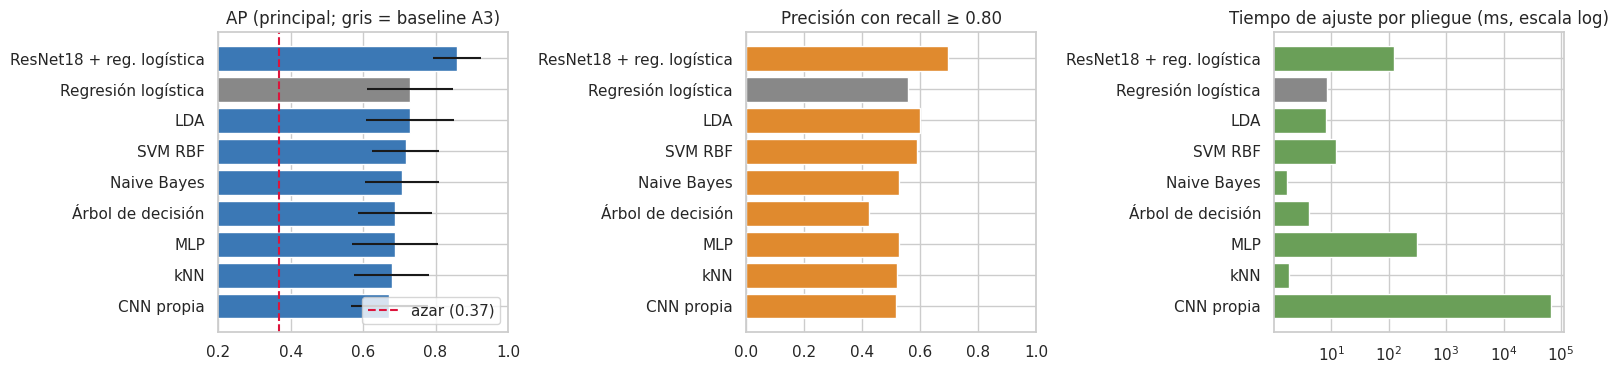

In [6]:
v = comp.drop(index=SIN_APRENDER).sort_values("AP")
col = ["#888888" if m == BASELINE else "#3b78b5" for m in v.index]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
ax[0].barh(v.index, v.AP, xerr=v.AP_desv, color=col); ax[0].axvline(PREV, color="crimson", ls="--", label=f"azar ({PREV:.2f})")
ax[0].set_xlim(0.2, 1); ax[0].set_title("AP (principal; gris = baseline A3)"); ax[0].legend(loc="lower right")
ax[1].barh(v.index, v["Prec@Rec80"], color=["#888888" if m == BASELINE else "#e08a2e" for m in v.index]); ax[1].set_xlim(0, 1); ax[1].set_title("Precisión con recall ≥ 0.80")
ax[2].barh(v.index, v.ajuste_ms, color=["#888888" if m == BASELINE else "#6a9f58" for m in v.index]); ax[2].set_xscale("log"); ax[2].set_title("Tiempo de ajuste por pliegue (ms, escala log)")
plt.tight_layout(); plt.show()

### Interpretación de la comparación (sección 3)
En este caso podemos ver claramente el modelo RestNet18 más el baseline que habíamos seleccionado en el avance 3, regresión logística, alcanzando una precisión promedio cercana a 0.86

El baseline solo está representado en la gráfica con una barrita en gris, su precisión está cercana a los 0.73.

Los demás modelos seleccionados quedaron por encima del aleatorio, lo cual es bueno y en el caso de la CNN propia fue la que quedó en precisión 0.6 más baja que todos los demás.

En escenarios donde se requiere un alto nivel de sensibilidad (es decir que se quiere detectar al menos el 80% de los casos positivos), la ResNet18 + Regresión Logística tiene también la mayor precisión 0.69

Los modelos más rápidos en entrenar son Naive Bayes y kNN, seguidos muy de cerca por Árbol de decisión, LDA y Regresión logística de 1 a 10ms

ResNet18 + reg. logística: Toma alrededor de 122.6ms de ajuste es un costo computacional sumamente bajo para el beneficio en precisión que aporta

El resultado más sorprendente: El bajo desempeño de la CNN propia en comparación con ResNet18 + Regresión Logística e incluso frente a modelos clásicos. Se esperaría que una red convolucional diseñada desde cero capturara mejor los patrones. Pero muy probablemente sale bajo porque ocupe una cantidad ingente de datos y un ajuste muy detallado de hiperparámetros.

## 4. Selección de los dos mejores (CV 5x3)


**Regla (fijada antes de mirar el ajuste):** entre los **seis modelos alternativos** (el baseline es la referencia y no compite), los dos con mayor **AP** en validación cruzada. Si el segundo y el tercero quedan empatados (diferencia menor que la desviación entre pliegues), se desempata con la precisión a recall ≥ 0.80 y, después, con el menor tiempo de ajuste. Así la selección no depende de una sola cifra ruidosa.

In [7]:
mej = comp.loc[ALTERNATIVOS].copy()
ordenado = mej.sort_values(["AP", "Prec@Rec80", "ajuste_ms"], ascending=[False, False, True])
tol = float(mej.AP_desv.mean())
segundo_y_tercero = ordenado.iloc[1:3]
if segundo_y_tercero.AP.iloc[0] - segundo_y_tercero.AP.iloc[1] < tol:                # empate técnico por el 2.º lugar
    desempate = segundo_y_tercero.sort_values(["Prec@Rec80", "ajuste_ms"], ascending=[False, True])
    DOS = [ordenado.index[0], desempate.index[0]]
else:
    DOS = list(ordenado.index[:2])
DOS_MANUAL = []   # OPCIONAL: escriba aquí los dos modelos que el equipo decida ajustar (p. ej. ["LDA", "SVM RBF"]); vacío = regla de la sección 4
if DOS_MANUAL: DOS = list(DOS_MANUAL)
display(Markdown(f"**Modelos seleccionados para ajuste:** `{DOS[0]}` (AP = {comp.loc[DOS[0], 'AP']:.3f}) y `{DOS[1]}` (AP = {comp.loc[DOS[1], 'AP']:.3f}). "
                 f"Tolerancia de empate = {tol:.3f} (desviación media entre pliegues)."))
display(mej.loc[ordenado.index, ["AP", "AP_desv", "Prec@Rec80", "ROC_AUC", "ajuste_ms"]].round(3).assign(seleccionado=lambda d: d.index.isin(DOS)))
print(f"Baseline (referencia, no compite): AP = {comp.loc[BASELINE, 'AP']:.3f}")

**Modelos seleccionados para ajuste:** `ResNet18 + reg. logística` (AP = 0.859) y `LDA` (AP = 0.729). Tolerancia de empate = 0.102 (desviación media entre pliegues).

,AP,AP_desv,Prec@Rec80,ROC_AUC,ajuste_ms,seleccionado
modelo,,,,,,
ResNet18 + reg. logística,0.859,0.066,0.695,0.888,122.569,True
LDA,0.729,0.122,0.600,0.807,8.233,True
SVM RBF,0.717,0.093,0.590,0.783,12.064,False
Naive Bayes,0.708,0.101,0.526,0.784,1.736,False
Árbol de decisión,0.688,0.103,0.424,0.733,4.140,False
MLP,0.688,0.118,0.528,0.777,312.339,False
kNN,0.679,0.104,0.521,0.778,1.881,False
CNN propia,0.673,0.106,0.518,0.758,66817.714,False


Baseline (referencia, no compite): AP = 0.729


### Justificación de la selección de los dos mejores (sección 4)

Se seleccionó tanto la ResNet18 + reg. logística (AP = 0.859) y LDA (AP = 0.729)

Estuvimos buscando una regla lo más completa posible que ya que el Average Precisión ayuda mucho frente al Accuracy. Se evalúa al modelo en todo lo posible y el hacer la cross validation con una restricción operativa de sensibilidad del recall >=0.8, permite no quedar sesgado por alguna variación grande que no tenga sustento. El desempate es simplemente quien lo hace más rápido.

No cambiaríamos la regla usada, pero si a lo mejor habría que usar algún criterio de desempate dependiendo del entorno en donde corra.

El baseline queda de referencia para que con el mínimo esfuerzo sentar una base, en donde si un modelo es muy complejo la complejidad quede descartada si rinde igual o peor.

Los 2 modelos seleccionados no son de la misma familia pertenecen a paradigmas distintos de aprendizaje. El ResNet + reg. logística pertenece a las redes neuronales profundas y al aprendizaje por transferencia (transfer learning) y LDA pertenece a los modelos estadísticos y geométricos clásicos de clasificación y reducción de dimensionalidad.

* LDA representa la escuela tradicional: que es rápida, lineal y está basada en estadísticas directas sobre los datos de entrada

* ResNet18 + Regresión Logística representa el paradigma moderno, utiliza un extractor no lineal ultracomplejo para capturar jerarquías visuales profundas antes de realizar la clasificación final.


## 5. Ajuste fino de los dos mejores

### 5.1 Diseño de la búsqueda
- **Método:** búsqueda aleatoria (`RandomizedSearchCV`) sobre distribuciones (log-uniformes para escalas como `C`, `gamma`, `alpha` y tasa de aprendizaje), con **120 configuraciones por modelo** (60 para el MLP, que es más costoso). Una búsqueda aleatoria explora mejor un espacio de varias dimensiones que una rejilla del mismo costo (Bergstra y Bengio, 2012; Géron, 2022, cap. 2, *Fine-Tune Your Model*).
- **Criterio:** AP medio en CV agrupada **5×2** sobre *train* (10 ajustes por configuración).
- **Qué se ajusta:** hiperparámetros de regularización, de kernel/arquitectura y de optimización según el modelo (tabla siguiente). El espacio está definido para los seis alternativos; por ejemplo, el del MLP incluye tamaño y número de capas, **función de activación**, regularización L2 y **tasa de aprendizaje**, y se usaría si ese modelo quedara entre los dos mejores.
- **Honestidad de la estimación:** la mejor configuración de una búsqueda tiene un AP *optimista* porque se eligió sobre los mismos pliegues. Por eso se añade una **validación cruzada anidada** (5.3) —la búsqueda se repite dentro de cada pliegue externo— y una comprobación en el conjunto de **validación**, que no participó en la búsqueda.

In [8]:
ESPACIOS = {
    "Regresión logística": {"C": loguniform(1e-3, 1e2), "penalty": ["l1", "l2"], "class_weight": [None, "balanced"], "solver": ["liblinear"]},
    "LDA":                 {"solver": ["lsqr"], "shrinkage": uniform(0.0, 1.0)},
    "Naive Bayes":         {"var_smoothing": loguniform(1e-9, 1e-1)},
    "kNN":                 {"n_neighbors": randint(3, 60), "weights": ["uniform", "distance"], "p": [1, 2]},
    "Árbol de decisión":   {"max_depth": randint(2, 9), "min_samples_leaf": randint(1, 25), "min_samples_split": randint(2, 30),
                            "ccp_alpha": loguniform(1e-4, 1e-1), "criterion": ["gini", "entropy"], "class_weight": [None, "balanced"]},
    "SVM RBF":             {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-4, 1e0), "class_weight": [None, "balanced"]},
    "ResNet18 + reg. logística": {"pca__n_components": [8, 16, 32, 64, 128], "clf__C": loguniform(1e-4, 1e0), "clf__class_weight": [None, "balanced"]},
    "CNN propia":         {"base": [8, 16, 24], "dropout": uniform(0.1, 0.5), "activation": ["relu", "leaky_relu", "elu"],
                            "lr": loguniform(1e-4, 5e-3), "weight_decay": loguniform(1e-5, 1e-2)},
    "MLP":                 {"hidden_layer_sizes": [(8,), (16,), (32,), (64,), (16, 8), (32, 16), (64, 32)], "activation": ["relu", "tanh", "logistic"],
                            "alpha": loguniform(1e-4, 1e0), "learning_rate_init": loguniform(1e-4, 1e-1)},
}
N_ITER = {m: (60 if m == "MLP" else 20 if m == "CNN propia" else 120) for m in ALTERNATIVOS}      # la CNN es mucho más costosa
es_img = lambda m: ESPACIO.get(m) == "img"
display(pd.DataFrame({"hiperparámetros explorados": {m: ", ".join(ESPACIOS[m]) for m in DOS},
                      "configuraciones": {m: N_ITER[m] for m in DOS}}))

,hiperparámetros explorados,configuraciones
ResNet18 + reg. logística,"pca__n_components, clf__C, clf__class_weight",120
LDA,"solver, shrinkage",120


In [9]:
SPLITS = [(tri, tei) for _, tri, tei in folds(ytr, gtr, reps=2)]          # 10 particiones agrupadas
BUSQ = {}
for m in DOS:
    t0 = time.perf_counter()
    spl = SPLITS[:5] if es_img(m) else SPLITS                                   # CNN: 5 particiones (1 repetición) para acotar el costo
    rs = RandomizedSearchCV(clone(MODELOS[m]), ESPACIOS[m], n_iter=N_ITER[m], scoring="average_precision", cv=spl,
                            random_state=SEED, n_jobs=(1 if es_img(m) else -1), refit=True, return_train_score=True).fit(ES(m)["tr"], ytr)
    BUSQ[m] = rs
    base_ap = comp.loc[m, "AP"]
    print(f"{m}: {N_ITER[m]} configuraciones × {len(spl)} particiones = {N_ITER[m] * len(spl)} ajustes en {time.perf_counter() - t0:.0f} s · "
          f"AP sin ajustar (5×3) = {base_ap:.3f} → mejor AP de la búsqueda = {rs.best_score_:.3f}")
    print("   mejores hiperparámetros:", {k: (round(float(v), 5) if isinstance(v, (np.floating, float)) else v) for k, v in rs.best_params_.items()})

ResNet18 + reg. logística: 120 configuraciones × 10 particiones = 1200 ajustes en 46 s · AP sin ajustar (5×3) = 0.859 → mejor AP de la búsqueda = 0.877
   mejores hiperparámetros: {'clf__C': 0.01626, 'clf__class_weight': None, 'pca__n_components': 32}
LDA: 120 configuraciones × 10 particiones = 1200 ajustes en 9 s · AP sin ajustar (5×3) = 0.729 → mejor AP de la búsqueda = 0.752
   mejores hiperparámetros: {'shrinkage': 0.03439, 'solver': 'lsqr'}


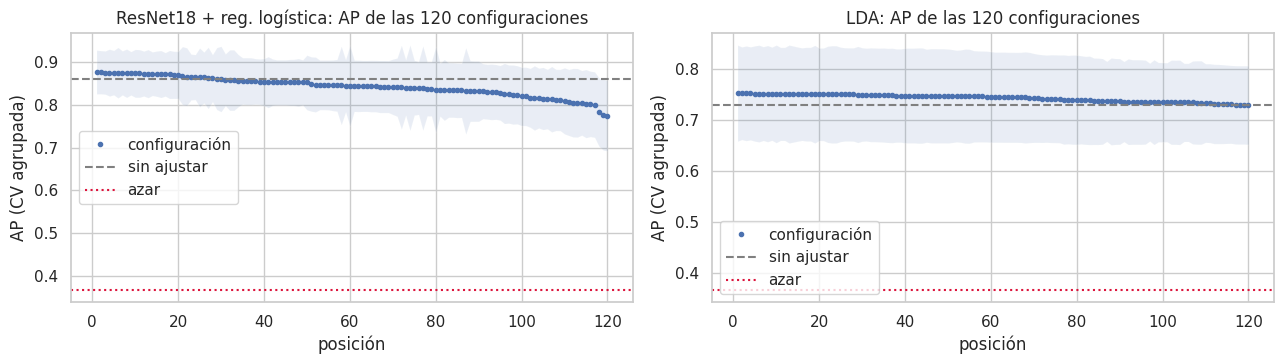


ResNet18 + reg. logística: 5 mejores configuraciones


,clf__C,clf__class_weight,pca__n_components,mean_test_score,std_test_score,mean_train_score,mean_fit_time
0,0.0163,None,32,0.8766,0.0511,0.9456,0.0318
1,0.0771,None,32,0.8761,0.0505,0.9521,0.0590
2,0.1871,None,32,0.8753,0.0505,0.9538,0.0320
3,0.0108,balanced,128,0.8752,0.0548,0.9933,0.0604
4,0.5908,None,32,0.8751,0.0519,0.9551,0.0332



LDA: 5 mejores configuraciones


,shrinkage,solver,mean_test_score,std_test_score,mean_train_score,mean_fit_time
0,0.0344,lsqr,0.7520,0.0940,0.7985,0.0091
1,0.1196,lsqr,0.7518,0.0905,0.7864,0.0044
2,0.0254,lsqr,0.7516,0.0925,0.7996,0.0078
3,0.1220,lsqr,0.7515,0.0910,0.7858,0.0088
4,0.0314,lsqr,0.7512,0.0931,0.7987,0.0045


In [10]:
# Evidencia de profundidad de la búsqueda: distribución del AP de todas las configuraciones y las 5 mejores
fig, ax = plt.subplots(1, len(DOS), figsize=(6.5 * len(DOS), 3.8))
ax = np.atleast_1d(ax)
for a, m in zip(ax, DOS):
    r = pd.DataFrame(BUSQ[m].cv_results_).sort_values("mean_test_score", ascending=False).reset_index(drop=True)
    a.plot(r.index + 1, r.mean_test_score, "o", ms=3, label="configuración")
    a.fill_between(r.index + 1, r.mean_test_score - r.std_test_score, r.mean_test_score + r.std_test_score, alpha=.12)
    a.axhline(comp.loc[m, "AP"], color="gray", ls="--", label="sin ajustar"); a.axhline(PREV, color="crimson", ls=":", label="azar")
    a.set_title(f"{m}: AP de las {len(r)} configuraciones"); a.set_xlabel("posición"); a.set_ylabel("AP (CV agrupada)"); a.legend()
plt.tight_layout(); plt.show()
for m in DOS:
    r = pd.DataFrame(BUSQ[m].cv_results_).sort_values("mean_test_score", ascending=False).head(5)
    cols = [c for c in r.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]
    print(f"\n{m}: 5 mejores configuraciones"); display(r[cols].rename(columns=lambda c: c.replace("param_", "")).round(4).reset_index(drop=True))

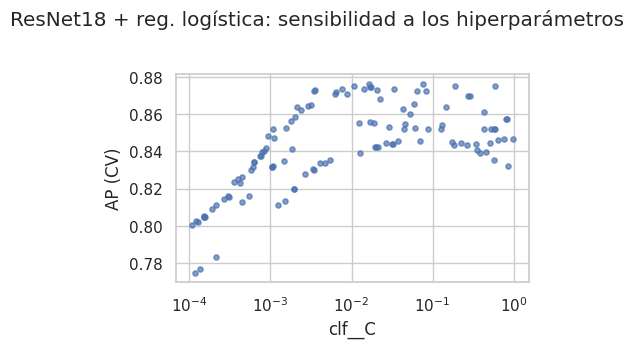

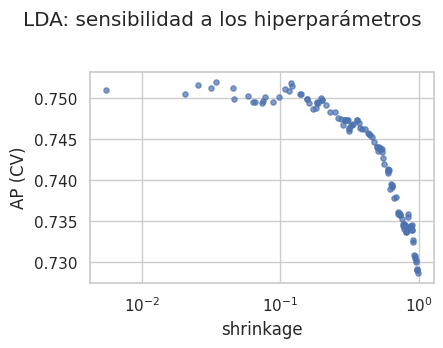

In [11]:
# Sensibilidad: cómo cambia el AP con cada hiperparámetro numérico (escala log cuando abarca varias décadas)
for m in DOS:
    r = pd.DataFrame(BUSQ[m].cv_results_)
    num = [c for c in r.columns if c.startswith("param_") and pd.api.types.is_numeric_dtype(pd.to_numeric(r[c], errors="coerce")) and pd.to_numeric(r[c], errors="coerce").nunique() > 6]
    if not num: continue
    fig, ax = plt.subplots(1, len(num), figsize=(4.6 * len(num), 3.4)); ax = np.atleast_1d(ax)
    for a, c in zip(ax, num):
        x = pd.to_numeric(r[c]); a.scatter(x, r.mean_test_score, s=14, alpha=.7)
        if x.min() > 0 and x.max() / x.min() > 50: a.set_xscale("log")
        a.set_xlabel(c.replace("param_", "")); a.set_ylabel("AP (CV)")
    fig.suptitle(f"{m}: sensibilidad a los hiperparámetros", y=1.02); plt.tight_layout(); plt.show()

### 5.2 Efecto del ajuste en entrenamiento, CV y validación
Se compara cada modelo **sin ajustar** y **ajustado** en tres lugares: AP en CV 5×3 de *train* (misma validación cruzada de la sección 3), AP en el conjunto de **validación** (no participó en la búsqueda) y la brecha entre el AP de entrenamiento y el de CV como señal de sobreajuste.

In [12]:
filas = []
for m in DOS:
    for etiqueta, est in [("sin ajustar", clone(MODELOS[m])), ("ajustado", clone(BUSQ[m].best_estimator_))]:
        res, _ = cv_modelo(est, ES(m)["tr"], ytr, gtr)
        fit = clone(est).fit(ES(m)["tr"], ytr)
        p_tr, p_va = fit.predict_proba(ES(m)["tr"])[:, 1], fit.predict_proba(ES(m)["va"])[:, 1]
        filas.append({"modelo": m, "versión": etiqueta, "AP_train": average_precision_score(ytr, p_tr), "AP_CV": res["AP"], "AP_CV_desv": res["AP_desv"],
                      "AP_val": average_precision_score(yva, p_va), "ROC_AUC_val": roc_auc_score(yva, p_va), "Prec@Rec80_val": prec_at_rec(yva, p_va),
                      "brecha_train−CV": average_precision_score(ytr, p_tr) - res["AP"], "ajuste_ms": res["ajuste_ms"]})
efecto = pd.DataFrame(filas).set_index(["modelo", "versión"])
display(efecto.round(3))

AP_train  AP_CV  AP_CV_desv  AP_val  ROC_AUC_val  Prec@Rec80_val  brecha_train−CV  ajuste_ms
modelo                    versión                                                                                                  
ResNet18 + reg. logística sin ajustar     0.984  0.859       0.066   0.627        0.748           0.591            0.125    107.942
                          ajustado        0.943  0.871       0.047   0.538        0.681           0.500            0.071     98.143
LDA                       sin ajustar     0.803  0.729       0.122   0.548        0.601           0.382            0.074      2.675
                          ajustado        0.794  0.724       0.118   0.527        0.554           0.372            0.069      2.873

### 5.3 Validación cruzada anidada (estimación sin optimismo)
Para cada pliegue externo (5 pliegues agrupados) la búsqueda se repite **solo con los datos de entrenamiento de ese pliegue** (30 configuraciones —6 para la CNN—, CV agrupada interna de 3 pliegues) y el modelo resultante se evalúa en el pliegue externo, que la búsqueda nunca vio. Se compara con el modelo sin ajustar en los **mismos** pliegues externos. Esta es la estimación que se usa para decidir si el ajuste realmente mejora y para comparar a los dos finalistas.

In [13]:
EXT = [(tri, tei) for _, tri, tei in folds(ytr, gtr, reps=1, seed=SEED + 100)]
filas, oof_nest = [], {}
for m in DOS:
    t0 = time.perf_counter(); ap_aj, ap_def = [], []; p_aj = np.zeros(len(ytr)); p_def = np.zeros(len(ytr))
    for tri, tei in EXT:
        rs = RandomizedSearchCV(clone(MODELOS[m]), ESPACIOS[m], n_iter=(6 if es_img(m) else 30), scoring="average_precision",
                                cv=StratifiedGroupKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=(1 if es_img(m) else -1), refit=True
                                ).fit(ES(m)["tr"].iloc[tri], ytr[tri], groups=gtr[tri])
        p_aj[tei] = rs.predict_proba(ES(m)["tr"].iloc[tei])[:, 1]
        p_def[tei] = clone(MODELOS[m]).fit(ES(m)["tr"].iloc[tri], ytr[tri]).predict_proba(ES(m)["tr"].iloc[tei])[:, 1]
        ap_aj.append(average_precision_score(ytr[tei], p_aj[tei])); ap_def.append(average_precision_score(ytr[tei], p_def[tei]))
    oof_nest[m] = p_aj
    d = np.array(ap_aj) - np.array(ap_def)
    filas.append({"modelo": m, "AP_anidado_ajustado": np.mean(ap_aj), "AP_anidado_desv": np.std(ap_aj), "AP_sin_ajustar_mismos_pliegues": np.mean(ap_def),
                  "mejora_media": d.mean(), "mejora_desv": d.std(), "pliegues_que_mejoran": int((d > 0).sum()),
                  "Prec@Rec80_anidado": prec_at_rec(ytr, p_aj), "ROC_AUC_anidado": roc_auc_score(ytr, p_aj), "t_s": time.perf_counter() - t0})
nest = pd.DataFrame(filas).set_index("modelo")
display(nest.round(3))

,AP_anidado_ajustado,AP_anidado_desv,AP_sin_ajustar_mismos_pliegues,mejora_media,mejora_desv,pliegues_que_mejoran,Prec@Rec80_anidado,ROC_AUC_anidado,t_s
modelo,,,,,,,,,
ResNet18 + reg. logística,0.859,0.039,0.853,0.006,0.023,3,0.691,0.865,13.947
LDA,0.769,0.062,0.789,-0.020,0.027,1,0.594,0.806,2.271


### Interpretación del ajuste fino (secciones 5.1 a 5.3)

Con el ajuste fino buscábamos saber si afinar los hiperparámetros mejoraba los dos modelos finalistas y la respuesta es que casi no lo hizo. En la validación cruzada anidada, que es la estimación más honesta porque la búsqueda se repite sin ver el pliegue de evaluación, ResNet18 junto con regresión logística pasa de 0.853 a 0.859 de AP, una mejora de 0.006 que ocurrió en solo 3 de 5 pliegues y es menor que la variación entre pliegues que fue de 0.023. LDA incluso empeoró en promedio 0.020 y solo mejoró en un pliegue. Por lo tanto, ninguna de las dos mejoras se distingue del ruido; además mencionar que el rendimiento de ambos modelos depende de su diseño y no de la configuración.

El AP que reporta la búsqueda es optimista porque la mejor de 120 configuraciones se eligió sobre los mismos pliegues en que se mide, así que parte de su "ventaja" es suerte. En ResNet18 esto se ve en el paso de 0.877 en la búsqueda a 0.859 en la validación anidada, en cambio, en LDA no se puede leer de la misma forma porque su variación entre pliegues es muy grande (entre 0.06 y 0.12) y ambas estimaciones usan pliegues diferentes. Lo que sí mejoró con el ajuste en ResNet18 fue la brecha entre entrenamiento y validación cruzada, que bajó de 0.125 a 0.071, es decir, el modelo ajustado se sobreajusta menos. Sin embargo, en el conjunto de validación el AP no mejoró, de 0.627 pasó a 0.538, aunque con tan pocos frutos esa cifra es muy inestable y la tomamos solo como una advertencia.

Ahora, las gráficas de sensibilidad confirman que pocos hiperparámetros importan. En ResNet18, un valor de C demasiado pequeño regulariza en exceso y hace caer el AP, pero desde aproximadamente 10⁻² el desempeño se mantiene estable entre 0.84 y 0.875, y las mejores configuraciones coinciden en usar 32 componentes PCA. En LDA, el parámetro shrinkage solo reduce ligeramente el AP cuando se acerca a 1, un cambio pequeño comparado con su variabilidad. Es importante mencionar que el espacio de búsqueda fue suficiente para ver estas tendencias, ya que cientos de configuraciones distintas terminaron en una conjunto de resultados parecidos, lo que indica que el límite lo marcan los datos y no los hiperparámetros.

Finalmente, podríamos decir que con más tiempo exploraríamos más allá de la regresión logística, otras versiones de ResNet o ajustar parcialmente la red *fine tunning* y ampliaríamos el conjunto de datos que es lo que más ayudaría a reducir el ruido.

## 6. Elección del modelo individual final


### 6.1 Criterios
La decisión no se reduce a la métrica principal. Se consideran, en este orden:

1. **Desempeño honesto** (AP anidado) y **precisión con recall ≥ 0.80**, que es lo que le importa al negocio.
2. **Estabilidad:** si la diferencia de AP entre los dos finalistas es menor que su desviación entre pliegues, hay **empate técnico** y deciden los criterios siguientes.
3. **Interpretabilidad:** SOLID debe poder explicar por qué se expulsa un fruto y qué variable de proceso vigilar.
4. **Costo computacional y de mantenimiento:** tiempo de ajuste y de predicción, número de hiperparámetros, sensibilidad a la escala y a la deriva de la iluminación.
5. **Riesgo de sobreajuste:** brecha entre entrenamiento y CV.

| Modelo | Interpretabilidad | Hiperparámetros a mantener | Sensible a la escala | Probabilidades |
|---|---|---|---|---|
| Regresión logística | Alta (coeficientes con signo) | 1–2 | Sí (ya estandarizado) | Calibradas razonablemente |
| LDA | Alta (dirección discriminante) | 1 | Sí | Razonables bajo normalidad |
| Naive Bayes | Media | 1 | No | Sobreconfiadas |
| Árbol de decisión | Alta si es poco profundo | 4–6 | No | Escalonadas |
| kNN | Baja (guarda todos los datos) | 3 | Sí | Poco finas |
| SVM RBF | Baja | 2–3 | Sí | Vía Platt (costo extra) |
| MLP | Baja | 5–6 | Sí | Pueden estar mal calibradas |
| ResNet18 + regresión logística | Baja (embeddings opacos) | 2–3 | Sí | Calibradas razonablemente; requiere el *backbone* en producción |
| CNN propia | Baja | 5–6 | Sí (imagen) | Pueden estar mal calibradas; requiere GPU/CPU y reentrenar con cada sesión de captura |

In [14]:
INTERP = {"Regresión logística": 3, "LDA": 3, "Árbol de decisión": 3, "Naive Bayes": 2, "kNN": 1, "SVM RBF": 1, "MLP": 1, "ResNet18 + reg. logística": 1, "CNN propia": 1}
ficha = pd.DataFrame({
    "AP_anidado": nest.AP_anidado_ajustado, "desv": nest.AP_anidado_desv, "Prec@Rec80_anidado": nest["Prec@Rec80_anidado"],
    "AP_val": [efecto.loc[(m, "ajustado"), "AP_val"] for m in DOS], "brecha_train−CV": [efecto.loc[(m, "ajustado"), "brecha_train−CV"] for m in DOS],
    "ajuste_ms": [efecto.loc[(m, "ajustado"), "ajuste_ms"] for m in DOS], "pred_ms": [comp.loc[m, "pred_ms_por_fruto"] for m in DOS], "interpretabilidad(1-3)": [INTERP[m] for m in DOS]}, index=DOS)
display(ficha.round(3))

a, b = DOS
dif = ficha.loc[a, "AP_anidado"] - ficha.loc[b, "AP_anidado"]
tol_fin = min(ficha.loc[a, "desv"], ficha.loc[b, "desv"])

MODELO_FINAL = "ResNet18 + reg. logística"       # <-- ESCRIBA AQUÍ el modelo individual elegido por el equipo (debe ser uno de los dos finalistas)

if MODELO_FINAL in DOS:
    FINAL_NOM = MODELO_FINAL
else:                    # solo para que las secciones 7 en adelante puedan ejecutarse mientras el equipo decide
    FINAL_NOM = ficha.AP_anidado.idxmax()
    print(f"AVISO: MODELO_FINAL está vacío o no es uno de {DOS}. Se usa TEMPORALMENTE '{FINAL_NOM}' (mayor AP anidado) solo para ejecutar las secciones siguientes. Defina MODELO_FINAL con la decisión del equipo.")
OTRO = b if FINAL_NOM == a else a
print(f"Diferencia de AP anidado entre los finalistas: {dif:+.3f} (desviación entre pliegues ≈ {tol_fin:.3f})")


,AP_anidado,desv,Prec@Rec80_anidado,AP_val,brecha_train−CV,ajuste_ms,pred_ms,interpretabilidad(1-3)
ResNet18 + reg. logística,0.859,0.039,0.691,0.538,0.071,98.143,72.636,1
LDA,0.769,0.062,0.594,0.527,0.069,2.873,0.023,3


Diferencia de AP anidado entre los finalistas: +0.090 (desviación entre pliegues ≈ 0.039)



### Justificación de la elección del modelo individual final

Se seleccionó ResNet18 + Regresión Logística como modelo final, debido a que presentó el mejor desempeño en la validación cruzada, alcanzando un AP de 0.859, frente a 0.769 de LDA. Además, obtuvo una mayor precisión con recall ≥ 0.80 (0.691 frente a 0.594), lo cual es especialmente relevante para SOLID, ya que buscamos detectar la mayor cantidad posible de arándanos defectuosos sin rechazar excesivamente fruta en buenas condiciones.

Uno de los principales factores que favorecen esta arquitectura es el uso de Transfer Learning, ya que permite aprovechar las características visuales extraídas por una red previamente entrenada, logrando un mejor desempeño que los modelos basados únicamente en características tradicionales.

En términos de estabilidad y sobreajuste, ambos modelos presentaron brechas similares entre entrenamiento y validación cruzada (0.071 para ResNet18 y 0.069 para LDA). Esto indica que ninguno mostró una ventaja importante en este criterio, aunque será necesario continuar evaluando su capacidad de generalización con nuevas imágenes y condiciones de captura.

La principal desventaja de ResNet18 es su costo computacional e interpretabilidad. Su tiempo de predicción de 72.6 ms por fruto es considerablemente superior al de LDA (0.023 ms), además de requerir mantener el extractor de características preentrenado. También resulta más difícil explicar directamente qué características provocan el rechazo de un fruto. Estas limitaciones podrían mitigarse mediante aceleración por GPU, procesamiento paralelo y técnicas de explicabilidad visual.

En conclusión, se elige ResNet18 + Regresión Logística por su mayor capacidad de clasificación, priorizando la calidad de la selección sobre el costo computacional en esta etapa experimental. Se conservará LDA como modelo alternativo, debido a su velocidad, simplicidad e interpretabilidad, especialmente si las pruebas industriales muestran que ResNet18 no cumple con los tiempos de procesamiento requeridos.


### 6.2 Control de fuga por sesión de captura
Un modelo de imagen puede acertar por razones equivocadas: si los frutos buenos y malos se fotografiaron en sesiones distintas, la red podría reconocer el **fondo o la iluminación** en lugar del defecto (riesgo señalado desde el Avance 2). Se repite la evaluación de la ResNet18 con tres entradas: el recorte completo, **solo el fruto** (fondo en gris) y **solo el fondo** (fruto tapado). Si el fondo por sí solo predijera la clase, habría fuga.

In [15]:
if HAY_IMG:
    def emb_modo(modo):
        def rec(r):
            im = np.asarray(Image.open(IMG_ROOT / "output" / f"{r.crop_id}.png").convert("RGB")).copy(); h, w = im.shape[:2]
            yy, xx = np.ogrid[:h, :w]; d = np.hypot(xx - r.cx, yy - r.cy)
            if modo == "fondo": im[d <= r.radio * 1.10] = 128                    # tapa el fruto
            else:               im[d > r.radio * 1.05] = 128                     # deja solo el fruto
            R = int(round(r.radio)) + 20; cx, cy = int(round(r.cx)), int(round(r.cy))
            c = Image.fromarray(im).crop((max(0, cx - R), max(0, cy - R), min(w, cx + R), min(h, cy + R)))
            return np.asarray(c.resize((224, 224), Image.BILINEAR))
        z = np.stack([rec(r) for r in ALL.itertuples()]); z = (torch.from_numpy(z).permute(0, 3, 1, 2).float() / 255 - mu) / sd
        with torch.no_grad(): return torch.cat([red(z[i:i + 64]) for i in range(0, len(z), 64)]).numpy()
    filas = []
    for modo, E_ in [("recorte completo", EMB), ("solo el fruto", emb_modo("fruto")), ("solo el fondo (fruto tapado)", emb_modo("fondo"))]:
        F_ = pd.DataFrame(E_[:len(TR)], columns=ESPACIOS_X["emb"]["tr"].columns)
        r_, _ = cv_modelo(clone(MODELOS["ResNet18 + reg. logística"]), F_, ytr, gtr)
        filas.append({"entrada": modo, "AP": r_["AP"], "ROC_AUC": r_["ROC_AUC"], "AP_desv": r_["AP_desv"]})
    ctrl = pd.DataFrame(filas).set_index("entrada"); display(ctrl.round(3))
else:
    print("Sin imágenes: control omitido.")

,AP,ROC_AUC,AP_desv
entrada,,,
recorte completo,0.859,0.888,0.066
solo el fruto,0.860,0.887,0.046
solo el fondo (fruto tapado),0.428,0.574,0.061



### Interpretación del control de fuga por fondo

Los resultados muestran que la información más importante para la clasificación se encuentra en el fruto y no en el fondo de la imagen. Al utilizar únicamente el arándano, el modelo obtuvo un AP de 0.860, prácticamente idéntico al obtenido con el recorte completo (0.859). Esto indica que eliminar el fondo no afecta negativamente la capacidad de clasificación.

Por otro lado, al evaluar únicamente el fondo, el AP disminuyó considerablemente a 0.428, con un ROC-AUC de 0.574, cercano al comportamiento de un clasificador aleatorio. Esto sugiere que el modelo no depende principalmente de características del fondo o de las condiciones de captura para identificar los defectos.

Además, la desviación del AP disminuyó de 0.066 a 0.046 al utilizar únicamente el fruto, lo que sugiere una mayor estabilidad entre los pliegues de evaluación.

En conclusión, el experimento proporciona evidencia de que ResNet18 está aprendiendo principalmente características visuales del arándano y no del fondo, reduciendo la preocupación por una posible fuga de información asociada a las sesiones de captura. Sin embargo, todavía será necesario comprobar su comportamiento con imágenes de nuevas sesiones, diferentes condiciones de iluminación y distintos lotes de fruta para confirmar su capacidad de generalización.


## 7. Evaluación del modelo final en prueba (una sola vez)


Se fija el umbral con la **misma regla del Avance 3** —el umbral más alto con recall ≥ 0.80 en predicciones fuera de pliegue de *train*— y se reajusta el modelo con **train + validación**. Se evalúa **una única vez** en prueba junto con el baseline del Avance 3 (regresión logística con su umbral original), con IC 95 % por *bootstrap* de bloques. Los criterios son los de ese avance: C1 (AP mejor que el azar, con límite inferior del IC sobre la prevalencia), C2 (recall ≥ 0.80) y C3 (precisión ≥ 0.60).

In [16]:
MEJOR = clone(BUSQ[FINAL_NOM].best_estimator_)
# Umbral con predicciones fuera de pliegue de train (5 repeticiones), sin mirar validación ni prueba
_, oof5 = cv_modelo(MEJOR, ES(FINAL_NOM)["tr"], ytr, gtr, reps=5)
pr_, rc_, th_ = precision_recall_curve(np.tile(ytr, 5), oof5.ravel())
U = float(th_[rc_[:-1] >= REC_OBJ][-1])
print(f"Umbral del modelo final (mayor umbral con recall OOF ≥ {REC_OBJ}): {U:.3f}")

def boot_grupos(g, B, rng):
    u = np.unique(g); idx = {k: np.where(g == k)[0] for k in u}
    for _ in range(B): yield np.concatenate([idx[k] for k in rng.choice(u, len(u), replace=True)])

def evaluar(modelo, umbral, nombre, esp):
    f = clone(modelo).fit(esp["dev"], ydev); p = f.predict_proba(esp["te"])[:, 1]
    m = metricas(yte, p, umbral)
    bs = pd.DataFrame([metricas(yte[ix], p[ix], umbral) for ix in boot_grupos(gte, 1000, np.random.default_rng(SEED)) if yte[ix].min() != yte[ix].max()])
    ic = bs.quantile([.025, .975]).T.rename(columns={.025: "ic_inf", .975: "ic_sup"})
    return f, p, pd.DataFrame({nombre: pd.Series(m)}).join(ic.add_prefix(nombre + "_"))

base = LogisticRegression(C=C_BASE, class_weight="balanced", max_iter=5000)
f_fin, p_fin, r_fin = evaluar(MEJOR, U, "final", ES(FINAL_NOM))
f_base, p_base, r_base = evaluar(base, U_BASE, "baseline_A3", ESPACIOS_X["tab"])
res = r_fin.join(r_base)
orden = ["AP", "ROC_AUC", "Prec@Rec80", "recall_malo", "precision_malo", "F2", "bal_acc", "MCC", "accuracy"]
display(res.loc[orden].round(3))

Umbral del modelo final (mayor umbral con recall OOF ≥ 0.8): 0.301


,final,final_ic_inf,final_ic_sup,baseline_A3,baseline_A3_ic_inf,baseline_A3_ic_sup
AP,0.879,0.732,1.000,0.742,0.503,0.920
ROC_AUC,0.895,0.785,1.000,0.788,0.629,0.935
Prec@Rec80,0.708,0.559,1.000,0.630,0.367,0.880
recall_malo,0.800,0.579,1.000,0.850,0.600,1.000
precision_malo,0.696,0.526,0.857,0.607,0.367,0.846
F2,0.777,0.580,0.926,0.787,0.570,0.940
bal_acc,0.783,0.639,0.912,0.742,0.605,0.899
MCC,0.557,0.280,0.796,0.477,0.200,0.793
accuracy,0.780,0.649,0.900,0.720,0.568,0.894


,final,baseline_A3,cumple (final)
criterio,,,
C1. AP > azar (IC inf. > prevalencia),AP = 0.879 (IC 0.73–1.00) vs azar 0.400,AP = 0.742,Sí
C2. Recall(malo) ≥ 0.80,0.800,0.850,Sí
C3. Precisión(malo) ≥ 0.60,0.696,0.607,Sí


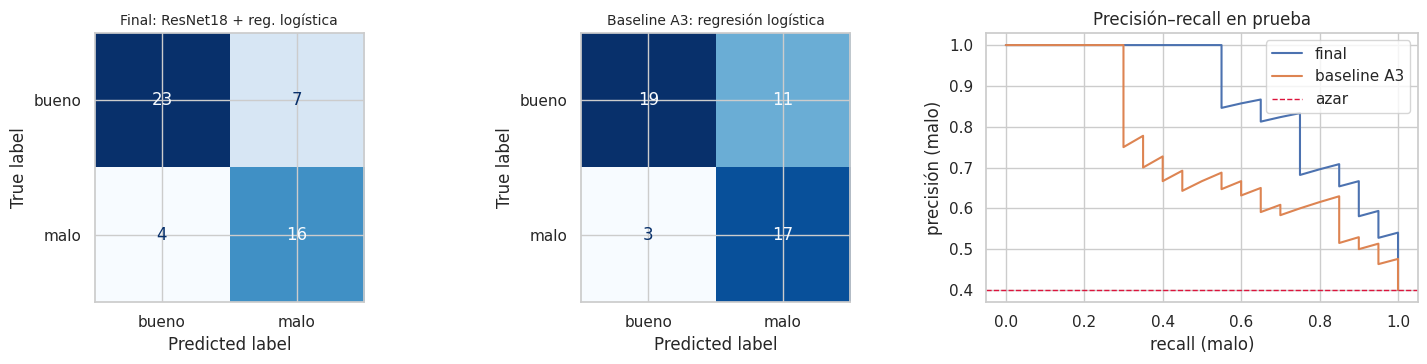

In [17]:
c1 = bool(res.loc["AP", "final_ic_inf"] > yte.mean()); c2 = bool(res.loc["recall_malo", "final"] >= REC_OBJ); c3 = bool(res.loc["precision_malo", "final"] >= 0.60)
display(pd.DataFrame({"criterio": ["C1. AP > azar (IC inf. > prevalencia)", "C2. Recall(malo) ≥ 0.80", "C3. Precisión(malo) ≥ 0.60"],
    "final": [f"AP = {res.loc['AP','final']:.3f} (IC {res.loc['AP','final_ic_inf']:.2f}–{res.loc['AP','final_ic_sup']:.2f}) vs azar {yte.mean():.3f}",
              f"{res.loc['recall_malo','final']:.3f}", f"{res.loc['precision_malo','final']:.3f}"],
    "baseline_A3": [f"AP = {res.loc['AP','baseline_A3']:.3f}", f"{res.loc['recall_malo','baseline_A3']:.3f}", f"{res.loc['precision_malo','baseline_A3']:.3f}"],
    "cumple (final)": ["Sí" if c1 else "No", "Sí" if c2 else "No", "Sí" if c3 else "No"]}).set_index("criterio"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (nom, p, u) in zip(ax[:2], [(f"Final: {FINAL_NOM}", p_fin, U), ("Baseline A3: regresión logística", p_base, U_BASE)]):
    ConfusionMatrixDisplay(confusion_matrix(yte, (p >= u).astype(int)), display_labels=["bueno", "malo"]).plot(ax=a, colorbar=False, cmap="Blues"); a.set_title(nom, fontsize=10)
for nom, p in [("final", p_fin), ("baseline A3", p_base)]:
    pt, rt, _ = precision_recall_curve(yte, p); ax[2].plot(rt, pt, label=nom)
ax[2].axhline(yte.mean(), color="crimson", ls="--", lw=1, label="azar"); ax[2].set_xlabel("recall (malo)"); ax[2].set_ylabel("precisión (malo)"); ax[2].set_title("Precisión–recall en prueba"); ax[2].legend()
plt.tight_layout(); plt.show()

### Interpretación de los resultados en prueba (sección 7)

El modelo final (ResNet18 + reg. logística) alcanza un average precision superior de 0.879 (con un intervalo de confianza de 0.73–1.00 frente a un azar de 0.400), superando al baseline A3 (0.742). Aunque existe un ligero traslape en el límite inferior del intervalo del modelo final con el puntaje del baseline, la tendencia refleja una mejora en la capacidad de predecir.

En términos de sensibilidad, el baseline A3 obtiene un recall ligeramente mayor (0.850) en comparación con el modelo final (0.800). Sin embargo, en precisión, el modelo final muestra una ventaja sustancial al registrar 0.696 frente a 0.607 del baseline

Registra el Modelo Final:
* 16 aciertos en la clase malo
* 23 aciertos en la clase bueno
* 4 falsos negativos: casos defectuosos clasificados como buenos
* 7 falsos positivos: productos buenos rechazados por error

El Baseline
* 17 aciertos en la clase malo
* 19 aciertos en la clase bueno
* 3 falso negativos: casos defectuosos clasificados como buenos
* 11 falsos positivos: productos buenos rechazados por error

El modelo al final reduce los falsos positivos de 11 a 7 que se traduce en el negocio en una disminución importante de los falsos rechazos, desperdicio innecesario de producto, logrando un balance más eficiente sin descuidar el control de calidad


## 8. Resumen y conclusiones


In [18]:
display(comp.loc[:, ["tipo", "rango_AP", "AP", "AP_desv", "Prec@Rec80", "ROC_AUC", "ajuste_ms", "pred_ms_por_fruto"]].round(3))
display(nest.round(3))
display(res.loc[["AP", "ROC_AUC", "Prec@Rec80", "recall_malo", "precision_malo", "F2", "MCC"]].round(3))
print("Modelo final (variable MODELO_FINAL):", FINAL_NOM, "| hiperparámetros:", BUSQ[FINAL_NOM].best_params_, "| umbral:", round(U, 3))

,tipo,rango_AP,AP,AP_desv,Prec@Rec80,ROC_AUC,ajuste_ms,pred_ms_por_fruto
modelo,,,,,,,,
ResNet18 + reg. logística,alternativo,1,0.859,0.066,0.695,0.888,122.569,72.636
Regresión logística,referencia (A3),2,0.729,0.119,0.558,0.806,8.499,0.034
LDA,alternativo,3,0.729,0.122,0.600,0.807,8.233,0.023
SVM RBF,alternativo,4,0.717,0.093,0.590,0.783,12.064,0.039
Naive Bayes,alternativo,5,0.708,0.101,0.526,0.784,1.736,0.026
Árbol de decisión,alternativo,6,0.688,0.103,0.424,0.733,4.140,0.024
MLP,alternativo,7,0.688,0.118,0.528,0.777,312.339,0.028
kNN,alternativo,8,0.679,0.104,0.521,0.778,1.881,0.042
CNN propia,alternativo,9,0.673,0.106,0.518,0.758,66817.714,5.055


,AP_anidado_ajustado,AP_anidado_desv,AP_sin_ajustar_mismos_pliegues,mejora_media,mejora_desv,pliegues_que_mejoran,Prec@Rec80_anidado,ROC_AUC_anidado,t_s
modelo,,,,,,,,,
ResNet18 + reg. logística,0.859,0.039,0.853,0.006,0.023,3,0.691,0.865,13.947
LDA,0.769,0.062,0.789,-0.020,0.027,1,0.594,0.806,2.271


,final,final_ic_inf,final_ic_sup,baseline_A3,baseline_A3_ic_inf,baseline_A3_ic_sup
AP,0.879,0.732,1.000,0.742,0.503,0.920
ROC_AUC,0.895,0.785,1.000,0.788,0.629,0.935
Prec@Rec80,0.708,0.559,1.000,0.630,0.367,0.880
recall_malo,0.800,0.579,1.000,0.850,0.600,1.000
precision_malo,0.696,0.526,0.857,0.607,0.367,0.846
F2,0.777,0.580,0.926,0.787,0.570,0.940
MCC,0.557,0.280,0.796,0.477,0.200,0.793


Modelo final (variable MODELO_FINAL): ResNet18 + reg. logística | hiperparámetros: {'clf__C': np.float64(0.01625772852521623), 'clf__class_weight': None, 'pca__n_components': 32} | umbral: 0.301


### Conclusiones del avance

Durante este avance se evaluaron diferentes modelos de aprendizaje automático, desde algoritmos estadísticos tradicionales como LDA, SVM y Naive Bayes, hasta redes neuronales convolucionales. El objetivo fue identificar una arquitectura capaz de clasificar arándanos buenos y defectuosos, considerando su desempeño predictivo y costo computacional.

El mejor modelo fue ResNet18 + Regresión Logística, alcanzando un Average Precision (AP) de 0.879 y un ROC-AUC de 0.895 en la evaluación final, superando al modelo de referencia, que obtuvo 0.742 y 0.788, respectivamente.

Uno de los principales hallazgos fue la ventaja del Transfer Learning, ya que permitió aprovechar características visuales aprendidas por ResNet18 sin necesidad de entrenar una red profunda desde cero. La CNN propia presentó un desempeño inferior (AP de 0.673) y un costo de entrenamiento considerablemente mayor.

Mediante validación cruzada y optimización de hiperparámetros se seleccionó una configuración de 32 componentes PCA, regularización C = 0.0163 y umbral de clasificación de 0.301. Sin embargo, la mejora obtenida mediante el ajuste fue pequeña, lo que sugiere que el principal beneficio proviene de la extracción de características de ResNet18.

También se coomprobó que el modelo no está aprendiendo por razones equivocadas. Al usar solo el fruto el AP fue de 0.860, prácticamente igual al del recorte completo mientras que con solo el fondo cayó a 0.428, muy cerca del comportamiento del azar. Esto indica que la clasificación se basa en el arándamo y no en la iluminación o la sesión de captura, aunque falta confirmarlo con lotes y condiciones de luz nuevas.

En cuanto al costo computacional, ResNet18 requiere de 72.6ms por fruto para predecir, frente a menos de 1 ms de LDA. Por ello, LDA se conserva como alternativa rápida e interpretable en caso de que la línea industrial exija mayor velocidad de procesamiento.

En conclusión, se recomienda a SOLID México continuar con la arquitectura ResNet18 + Regresión Logística, por presentar el mejor desempeño general y constituir una base prometedora para el desarrollo del sistema de clasificación industrial.


### Limitaciones y puntos por confirmar

- **Tamaño de muestra:** Los intervalos de confianza son amplios y se superponen con los del modelo de referencia, por lo que se requiere ampliar el conjunto de datos para confirmar la superioridad del modelo.

- **Generalización:** Es necesario validar con nuevas sesiones de captura, lotes y condiciones de iluminación, verificando que la agrupación por bloques evite dependencia entre entrenamiento y prueba.

- **Falsos positivos y negativos:** El modelo detecta el 80 % de los frutos defectuosos, dejando pasar aproximadamente el 20 %. Se debe determinar el costo industrial de cada error y verificar los criterios mínimos C2 y C3.

- **Tiempo de procesamiento:** La predicción requiere aproximadamente 72.6ms por fruto, por lo que será necesario evaluar aceleración mediante GPU, procesamiento paralelo y optimización para operación en tiempo real.

- **Alternativas pendientes:** No se exploraron ensambles, ajuste fino de ResNet18 ni técnicas de explicabilidad, que podrían mejorar el desempeño y permitir comprender mejor las decisiones del modelo.

El siguiente paso será comprobar que los resultados obtenidos en condiciones experimentales puedan mantenerse en una línea industrial, tanto en calidad de clasificación como en velocidad de procesamiento.

In [19]:
# Exportación de resultados agregados y del modelo final
import joblib
comp.round(4).to_csv(OUT_DIR / "comparacion_modelos.csv")
efecto.round(4).to_csv(OUT_DIR / "efecto_del_ajuste.csv")
nest.round(4).to_csv(OUT_DIR / "validacion_anidada.csv")
pd.concat({m: pd.DataFrame(BUSQ[m].cv_results_).sort_values("mean_test_score", ascending=False).head(20) for m in DOS}).drop(columns=["params"]).round(4).to_csv(OUT_DIR / "mejores_configuraciones.csv")
res.round(4).to_csv(OUT_DIR / "metricas_prueba.csv")
pd.DataFrame({"crop_id": TE.crop_id, "grupo": TE.grupo, "y": yte, "p_final": p_fin, "p_baseline": p_base}).to_csv(OUT_DIR / "predicciones_prueba.csv", index=False)
try:
    joblib.dump({"modelo": f_fin, "features": FEATS, "espacio": ESPACIO.get(FINAL_NOM, "tab"), "umbral": U, "nombre": FINAL_NOM, "params": BUSQ[FINAL_NOM].best_params_}, OUT_DIR / "modelo_final.joblib")
except Exception as e:
    print("No se pudo serializar el modelo completo:", repr(e)[:120])
json.dump({"modelo_final": FINAL_NOM, "finalistas": DOS, "umbral": U, "params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in BUSQ[FINAL_NOM].best_params_.items()},
           "n_iter": N_ITER, "seed": SEED}, open(OUT_DIR / "config_modelo_final.json", "w"), indent=1, default=str)
print("Guardado en", OUT_DIR.resolve(), "→", sorted(p.name for p in OUT_DIR.iterdir()))

Guardado en /content/drive/.shortcut-targets-by-id/1D3LM7dIWfg66NB2euECFRQF0hvwhPH31/ProyectoIntegrador/Datos/resultados_avance4 → ['comparacion_modelos.csv', 'config_modelo_final.json', 'efecto_del_ajuste.csv', 'mejores_configuraciones.csv', 'metricas_prueba.csv', 'modelo_final.joblib', 'predicciones_prueba.csv', 'validacion_anidada.csv']


# Declaración de uso de IA y contribución del equipo

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). *Claude Code* (Claude Sonnet 5.5)<br> [Modelo de lenguaje grande]. <br>https://claude.com/claude-code | Escribir el código de la libreta (carga de datos, validación cruzada<br> agrupada, borrador métricas, comparación de modelos, búsqueda <br>de hiperparámetros, modelos de imagen y control de fondo) <br>y redactar las secciones descriptivas del método | Celdas de código de las secciones 1 a 8 <br>y textos descriptivos de las secciones 2, 3, 4, 5, y 6.1 | Se revisaron los resultados en equipo,<br> se agregaron interpretación y se probó, <br> modificó borradores sugeridos por IA y se ejecutó por el equipo en Colab

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| José Luis Parada Gutiérrez | **1-3. Configuracion, metricas y modelado <br> 6. Evaluacion y eleccion del modelo individual final <br>8. Resumen y conclusiones <br>Conclusiones del avance<br> Decisión 3** |
| Kevin Rosario Cota Rodríguez | **5. Ajuste fino de los modelos**<br>**Decisión 2**<br>**Conclusiones del avance**|
| Rolando David Villarreal Martínez | **3. Interpretaciónde la comparación <br>4.Justificación de la selección de los dos mejores <br>7. Evaluación del modelo final en prueba (una sola vez)<br>Conclusiones del avance<br> Decisión 1** |

### Decisiones principales

<small>Documenten las tres decisiones que más influyeron en el avance, indicando qué alternativa se descartó.</small>

<small><b>Decisión 1:</b> Uso de la Precisión Promedio (AP) bajo Validación Cruzada con criterio de desempate por Precisión en Recall 0.80</small>

- <small>Justificación:<br/>

Definir la regla de decisión usando AP ayudó a hacer una evaluación completa del área bajo la curva Precisión-Recall, veíamos que era ideal para manejar. La restricción de Recall 0.80 aseguró que el modelo seleccionado mantuviera una alta sensibilidad de la operación ya que ayudó a minimizar falsos positivos 7 vs 11 del baseline y también terminó reduciendo el desperdicio de producto que sie era bueno. </small>
- <small>Alternativa descartada y motivo:<br>
Si nos basábamos únicamente en la exactitud (Accuracy) o en el Recall de forma aislada, el Accuracy ignora el costo de los errores en clases minoritarias, mientras que priorizar solo el Recall, como en el baseline, dejaba muy mal posicionada la precisión 0.607, incrementando en exceso los falsos rechazos en la línea. </small>

<small><b>Decisión 2:</b> Evaluar el ajuste de hiperparámetros con validación cruzada anidada</small>

- <small>Justificación: Cuando elegimos la mejor configuración entre 120 candidatas sobre los mismos datos, el resultado sale inflado, así que repetimos la búsqueda dentro de cada pliegue para obtener una cifra honesta. Basandonos en esa estimación, la mejora de ResNet18 fue de apenas 0.006 de AP, menor que el ruido entre pliegues y en LDA el ajuste incluso empeoró el resultado. </small>
- <small>Alternativa descartada y motivo: Se descartó el AP de la búsqueda (0.877) como medida del desempeño del modelo ajustado porque está inflado por haber elegido la mejor entre muchas configuraciones sobre los mismos datos. Tambié descartamos seguir invirtiendo tiempo en afinar hiperparámetros ya que las mejoras eran menores que el ruido y el límite parece estar en la cantidad de datos más que en la configuración.  </small>


<small><b>Decisión 3:</b> Utilizar Transfer Learning con ResNet18 como extractor de características y Regresión Logística como clasificador final.</small>

- <small>Justificación: Se decidió utilizar Transfer Learning para aprovechar las características visuales aprendidas por ResNet18 mediante su entrenamiento previo con grandes conjuntos de imágenes. Esta arquitectura alcanzó un AP de 0.859, superando a la CNN propia (0.673), sin necesidad de entrenar una red profunda desde cero. Además, permitió aprovechar mejor la cantidad limitada de imágenes disponibles y reducir considerablemente el costo de entrenamiento.</small>

- <small>Alternativa descartada y motivo: Se descartó utilizar una CNN entrenada desde cero, principalmente porque nuestro dataset es pequeño y buscamos aprovechar al máximo la información disponible. Al utilizar Transfer Learning con ResNet18, aprovechamos el conocimiento adquirido por un modelo entrenado previamente con millones de imágenes, lo que facilita identificar características visuales importantes para clasificar los arándanos. De esta manera, podemos obtener mejores resultados sin necesitar una cantidad tan grande de imágenes ni entrenar una red neuronal desde cero.</small>


